In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!nvidia-smi
!pip install -q -U ultralytics huggingface_hub

Sun Oct 25 07:46:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
from huggingface_hub import snapshot_download

path = snapshot_download(
    repo_id="Robbin123/ppe-dataset",
    repo_type="dataset",
    local_dir=r"C:\Users\USER\Desktop\4 курс\1 семестр\Анализ больших данных\ppe-dataset"
)
print("Датасет скачан в:", path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 31005 files:   0%|          | 0/31005 [00:00<?, ?it/s]

HTTP Error 429 thrown while requesting GET https://huggingface.co/api/resolve-cache/datasets/Robbin123/ppe-dataset/39bde3a1a54ae5700f73e4de2d55bc93f8c51c5c/train%2Flabels%2Fds2_helmet_jacket_01086.txt?%2Fdatasets%2FRobbin123%2Fppe-dataset%2Fresolve%2F39bde3a1a54ae5700f73e4de2d55bc93f8c51c5c%2Ftrain%2Flabels%2Fds2_helmet_jacket_01086.txt=&etag=%22db68c39943c657c9e7661a78b6dd469c1ae83c2d%22
Rate limited. Waiting 208.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/Robbin123/ppe-dataset/resolve/39bde3a1a54ae5700f73e4de2d55bc93f8c51c5c/train/labels/ds2_helmet_jacket_01088.txt
Rate limited. Waiting 208.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/datasets/Robbin123/ppe-dataset/resolve/39bde3a1a54ae5700f73e4de2d55bc93f8c51c5c/train/labels/ds2_helmet_jacket_01090.txt
Rate limited. Waiting 208.0s before retry [Retry 1/5].
HTTP Error 429 thrown while requesting HEAD https://huggingface.co/

Датасет скачан в: /content/C:\Users\USER\Desktop\4 курс\1 семестр\Анализ больших данных\ppe-dataset


In [ ]:
!cp -r /content/drive/MyDrive/industrial-vision/ppe-dataset /content/ppe
!find /content/ppe -maxdepth 3 -type d | head -30

cp: cannot stat '/content/drive/MyDrive/industrial-vision/ppe-dataset': No such file or directory
find: ‘/content/ppe’: No such file or directory


In [ ]:
!ls -la /content/
!ls -la /content/drive/MyDrive/industrial-vision/

total 24
drwxr-xr-x 1 root root 4096 Oct 25 07:47  .
drwxr-xr-x 1 root root 4096 Oct 25 07:14  ..
drwxr-xr-x 4 root root 4096 Oct 21 13:28  .config
drwxr-xr-x 6 root root 4096 Oct 25 08:17 'C:\Users\USER\Desktop\4 курс\1 семестр\Анализ больших данных\ppe-dataset'
drwx------ 5 root root 4096 Oct 25 07:46  drive
drwxr-xr-x 1 root root 4096 Oct 21 13:28  sample_data
ls: cannot access '/content/drive/MyDrive/industrial-vision/': No such file or directory


In [ ]:
import os, shutil

src = r"/content/C:\Users\USER\Desktop\4 курс\1 семестр\Анализ больших данных\ppe-dataset"
dst = "/content/ppe"

if os.path.exists(dst):
    shutil.rmtree(dst)
shutil.copytree(src, dst)
print("Скопировано в", dst)

Скопировано в /content/ppe


In [ ]:
yaml_text = """path: /content/ppe
train: train/images
val: val/images
test: test/images

nc: 3
names:
  0: helmet
  1: head
  2: vest
"""

with open("/content/ppe/data.yaml", "w", encoding="utf-8") as file:
    file.write(yaml_text)

print(yaml_text)

path: /content/ppe
train: train/images
val: val/images
test: test/images

nc: 3
names:
  0: helmet
  1: head
  2: vest



In [ ]:
from pathlib import Path

for folder in [
    "/content/ppe/train/images", "/content/ppe/train/labels",
    "/content/ppe/val/images",   "/content/ppe/val/labels",
    "/content/ppe/test/images",  "/content/ppe/test/labels",
]:
    p = Path(folder)
    print(("OK      " if p.exists() else "НЕТ     ") + folder)

OK      /content/ppe/train/images
OK      /content/ppe/train/labels
OK      /content/ppe/val/images
OK      /content/ppe/val/labels
OK      /content/ppe/test/images
OK      /content/ppe/test/labels


In [ ]:
!yolo detect train model=yolo26n.pt data=/content/ppe/data.yaml epochs=30 imgsz=640 batch=16 name=ppe_e01 project=/content/drive/MyDrive/industrial-vision/runs exist_ok=True

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ppe/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=N

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# датасет должен снова быть в /content/ppe (ячейки 3–5), затем:
!yolo detect train resume model=/content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/last.pt

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
WARNING ⚠️ model '/content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/last.pt' is not a resumable training checkpoint (missing epoch/optimizer state). Use 'resume' only to continue incomplete training. Starting new training instead.
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco8.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=Fals

In [ ]:
!yolo detect val model=/content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/best.pt data=/content/ppe/data.yaml split=test conf=0.3
!yolo detect val model=/content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/best.pt data=/content/ppe/data.yaml split=test

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.0±0.0 ms, read: 32.5±20.9 MB/s, size: 61.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/ppe/test/labels... 2751 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2751/2751 501.7it/s 5.5s
val: New cache created: /content/ppe/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 172/172 5.8it/s 29.5s
                   all       2751      10862      0.921      0.884      0.894      0.652
                helmet       2339       6939      0.939      0.896      0.907      0.662
                  head        145        962      0.919       0.86      0.871      0.568
                  ves

results.png


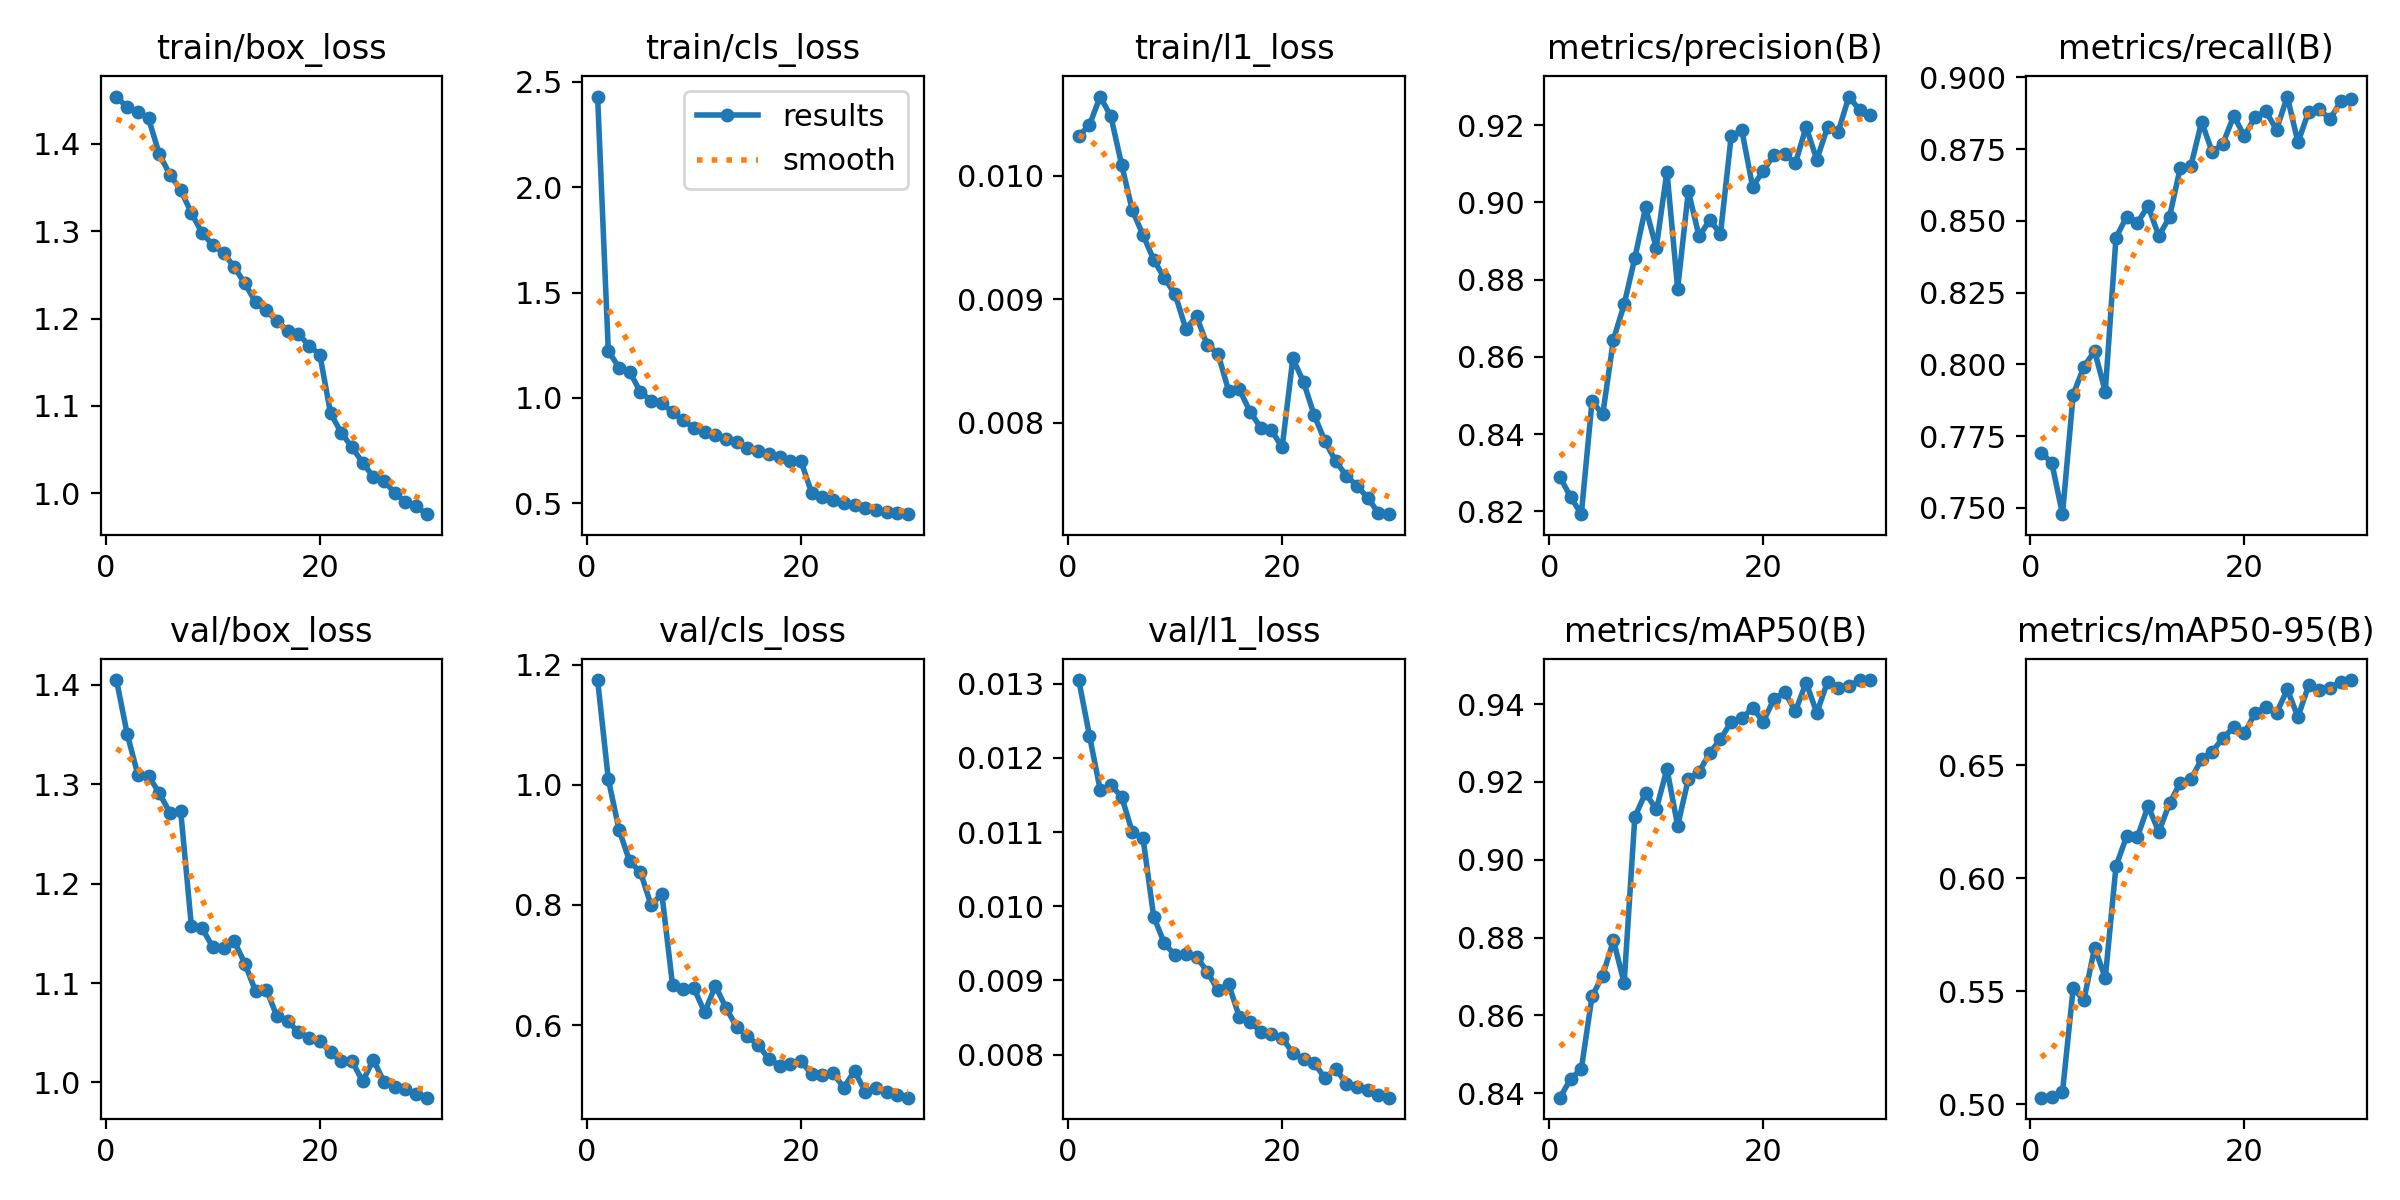

confusion_matrix.png


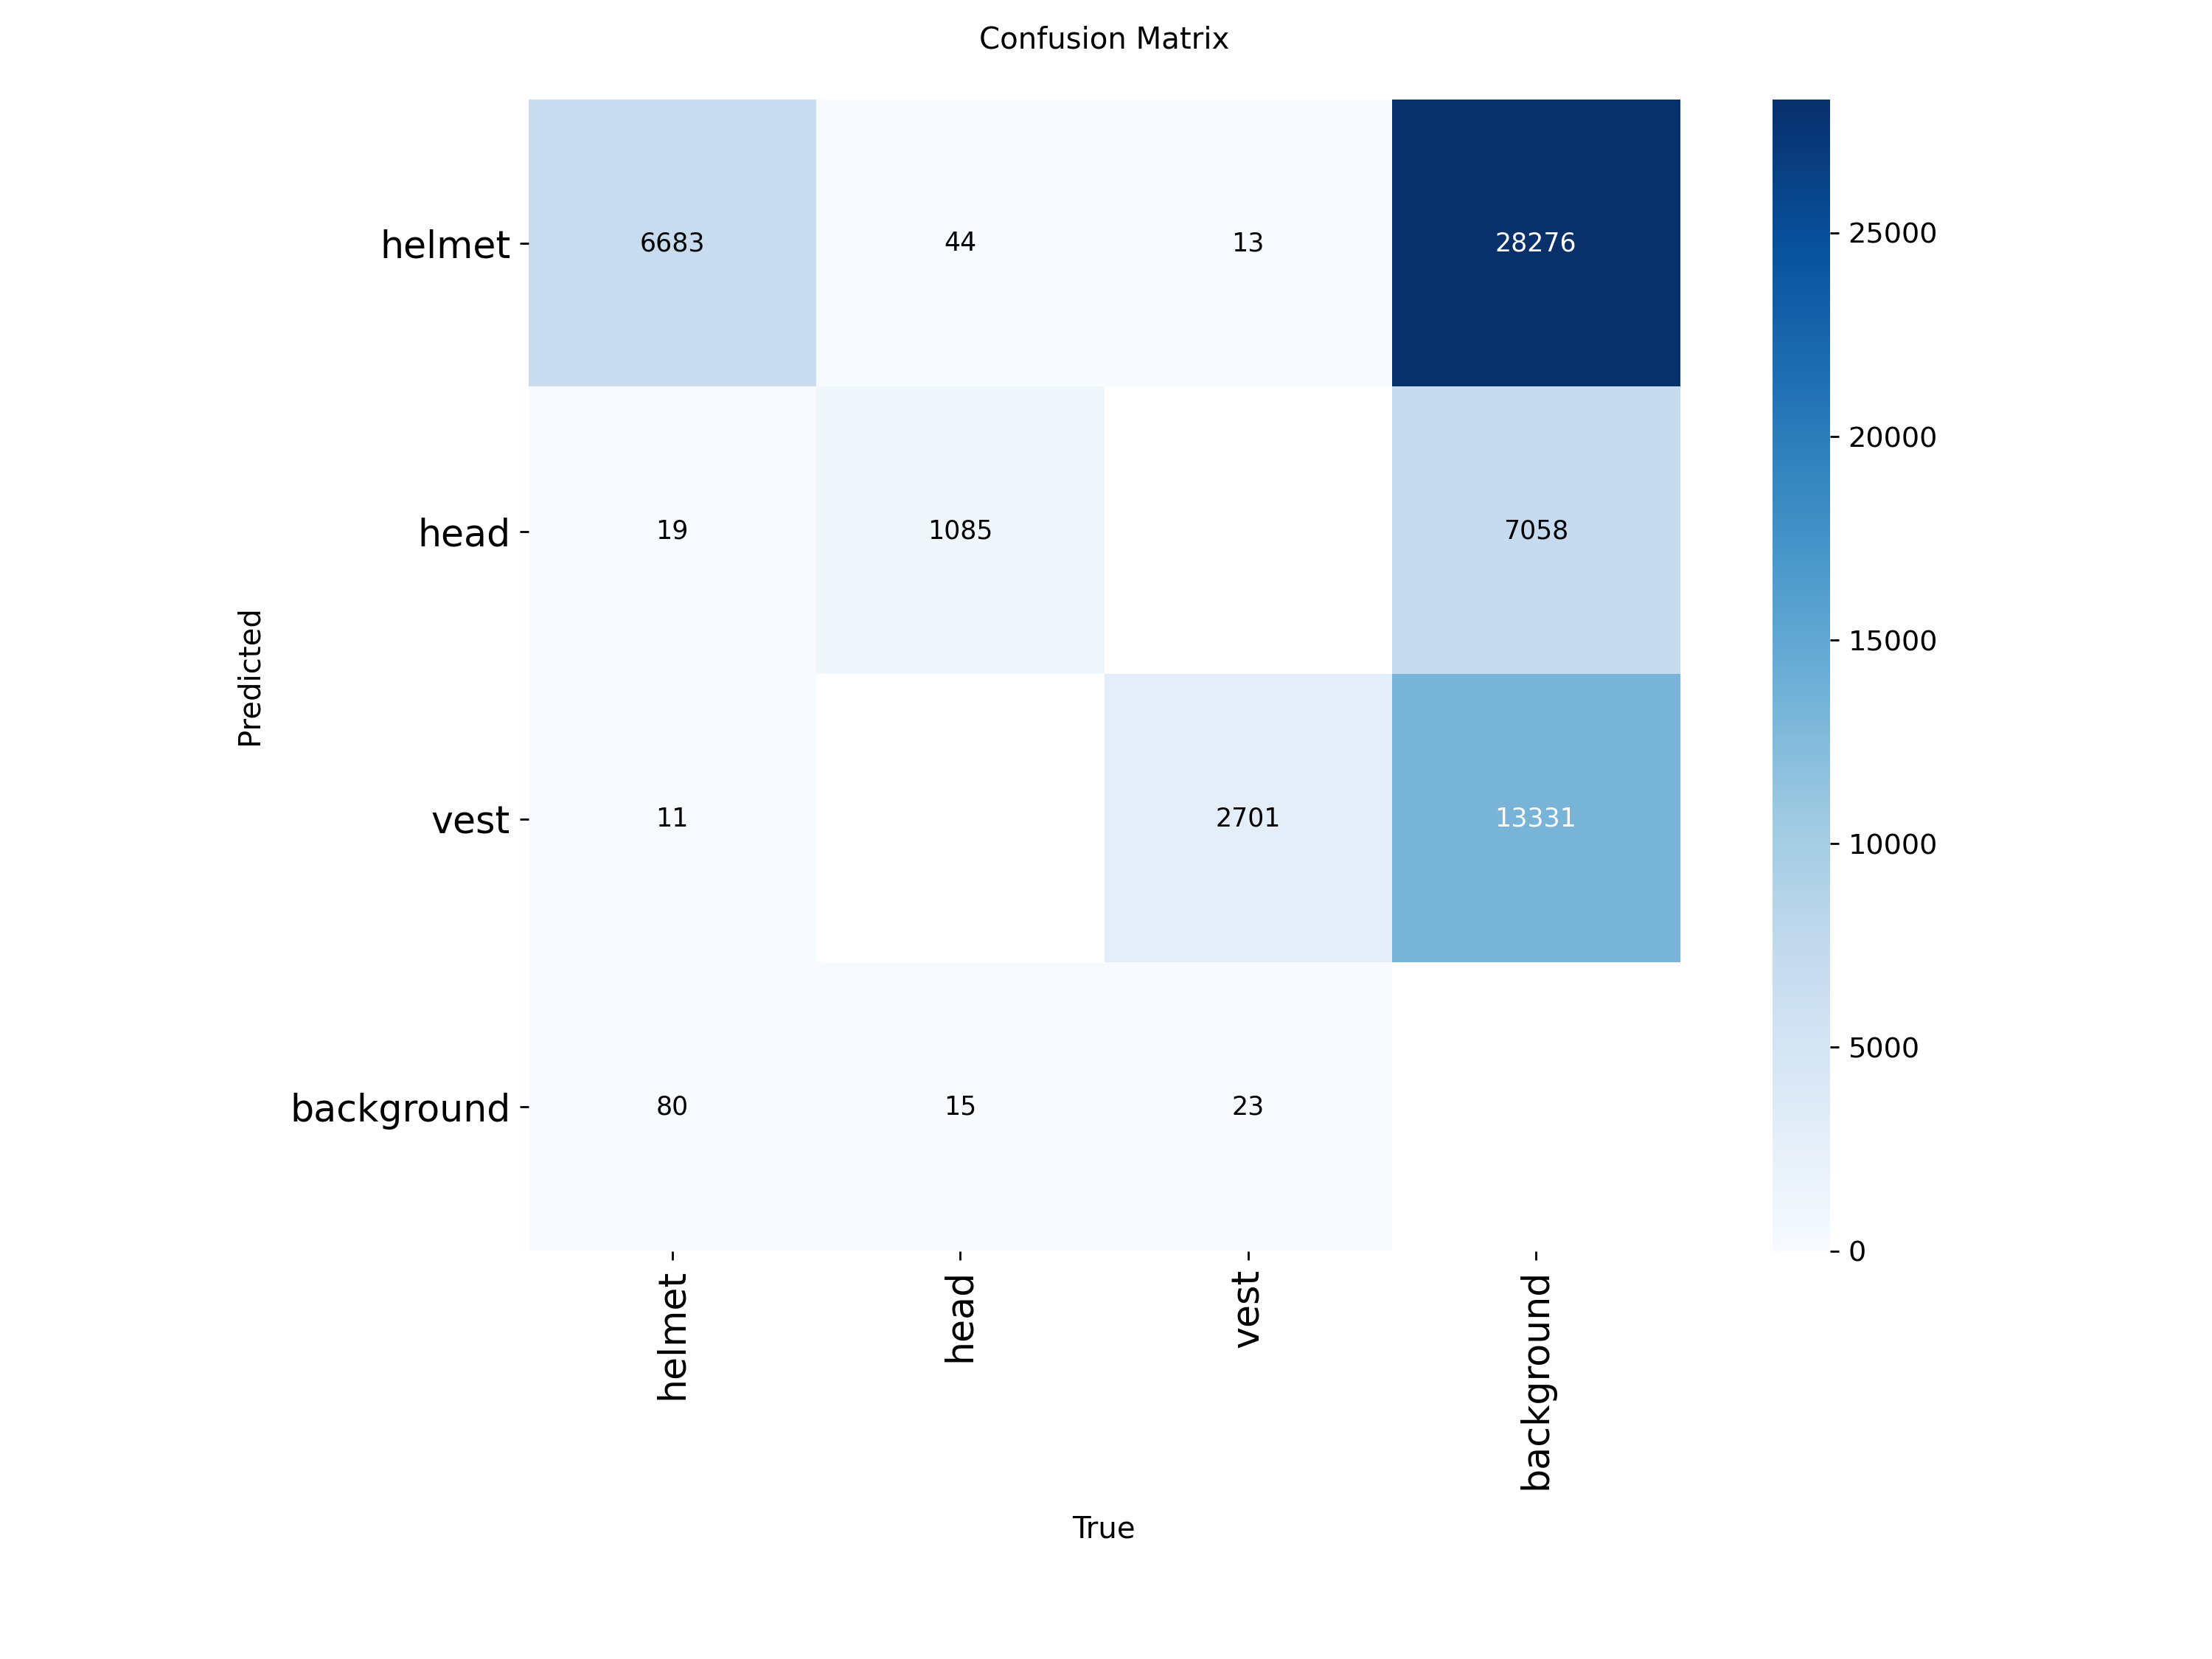

Файл не найден: PR_curve.png


In [ ]:
from IPython.display import Image, display
from pathlib import Path

results_dir = Path("/content/drive/MyDrive/industrial-vision/runs/ppe_e01")

for name in ["results.png", "confusion_matrix.png", "PR_curve.png"]:
    file_path = results_dir / name
    if file_path.exists():
        print(name)
        display(Image(filename=str(file_path)))
    else:
        print("Файл не найден:", name)

In [ ]:
!zip -r /content/drive/MyDrive/industrial-vision/ppe_e01.zip /content/drive/MyDrive/industrial-vision/runs/ppe_e01

  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/ (stored 0%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/ (stored 0%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/last.pt (deflated 11%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/weights/best.pt (deflated 11%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/args.yaml (deflated 53%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/labels.jpg (deflated 32%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/train_batch0.jpg (deflated 1%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/train_batch1.jpg (deflated 2%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/train_batch2.jpg (deflated 1%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/results.csv (deflated 62%)
  adding: content/drive/MyDrive/industrial-vision/runs/ppe_e01/train_batch12500.jpg (deflated 8%)
  add